# CHAZ intensity

The [tracks notebook](tracks.ipynb) found that our ERA5 run reaches the US coast about as often as
the CHAZ team's, and that the two differ in how long their intensity members last. This notebook
looks at the intensity model around the globe and tests the options of `chaz` that change it:

- `--land fine` reads the land term at the storm's position on the 1/12° land mask rather than in
  the 2° cell it is in (section 2)
- `--intensity refit` refits the water and land regressions on our ERA5 environment along the
  observed tracks of 1981–2012 (sections 3 and 4)
- `--intensity refit-pi` and `--intensity refit-basin` also draw the random error from observed
  steps with similar ring PI, and then from steps in the same basin as well (section 4)

Every run covers 1981–2019 with 10 track realizations of 40 intensity members. They use the same
random seeds, so they have the same tracks and differ only in intensity. The refit options read land
as `--land fine` does, since they are fit on it. 'shipped' is the run with the public code's
settings, the one the tracks notebook calls 'ours'.

`ocr.risks.hurricane.validate` compares each set with IBTrACS by the same rules. IBTrACS's wind is
USA_WIND, or where USA_WIND is missing, the WMO agency's wind converted to a 1-minute wind as
CLIMADA converts it (`landfall.observed_records`). USA_WIND in the Southern Hemisphere and western
Pacific comes from JTWC, which stops following a storm at extratropical transition; the regional
agencies keep following it, and their records count at any stage of the storm, as HURDAT's do in
the North Atlantic. The rules:

- landfalls by country: each storm's first crossing from sea onto a country's land, on the
  Natural Earth 1:10m countries at 1/12°, timed to 10 minutes and counted at the member's wind
  interpolated to that time. This is the first-crossing rule of Emanuel (2025), adapted as
  [landfall.ipynb](landfall.ipynb) describes
- time at 64 and 96 kt: 6-hourly points over sea in the regions of `validate.REGIONS` and, for
  North Atlantic storms, in six North Atlantic regions
- storms first reaching 34 kt, by where they reach it
- US landfalls on the Atlantic and Gulf coasts, by the same rule

Section 5 also scores the sets with landfalls counted at each storm's strongest crossing and its
last offshore wind, the sensitivity test of landfall.ipynb.

Rates are per year, and CHAZ's per intensity member. North Atlantic quantities (US landfalls and
time in the North Atlantic regions) are scaled so that each set's North Atlantic storm count
matches the observed one; the rest are not scaled. Section 4 gives the North Atlantic ratios
without the scaling as well. A storm belongs to the year of its first record.

All the sets make about as many storms as observed. The refit options bring more members to
34 kt: about 94 a year, against 85.0 with the shipped model and 88.6 observed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ocr.risks.hurricane import meanstd, refit, validate

RUN = 'TCGI_CRH_PI'
FINE = f'{RUN}-land-fine'
SOURCES = {
    'CHAZ team': 'chaz-team',
    'shipped': RUN,
    'fine land': FINE,
    'refit': f'{FINE}-intensity-refit',
    'refit-pi': f'{FINE}-intensity-refit-pi',
    'refit-basin': f'{FINE}-intensity-refit-basin',
    'refit-basin, fit 1981-1999': f'{FINE}-intensity-refit-basin-fit-1981-1999',
}
COLORS = {
    'CHAZ team': '#eb6834',
    'shipped': '#2a78d6',
    'fine land': '#8a5cc7',
    'refit': '#9c9a92',
    'refit-pi': '#e0a526',
    'refit-basin': '#1baf7a',
    'refit-basin, fit 1981-1999': '#0e6b4a',
}
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
tables = {'IBTrACS': validate.load('ibtracs')} | {k: validate.load(v) for k, v in SOURCES.items()}
YEARS = range(1981, 2020)
rates = validate.metrics(tables, YEARS)  # per year, 1981-2019


def vs_observed(rows, sources=None, digits=2):
    """IBTrACS per year, and each source over IBTrACS, for the rows IBTrACS has."""
    table = rates.loc[rows, ['IBTrACS', *(sources or SOURCES)]]
    table = table[table['IBTrACS'] > 0]
    ratio = table.drop(columns='IBTrACS').div(table['IBTrACS'], axis=0)
    observed = table[['IBTrACS']].rename(columns={'IBTrACS': 'IBTrACS per yr'})
    return pd.concat([observed, ratio], axis=1)


pd.DataFrame(
    {
        name: {
            'members per year': table['members'].mean(),
            'storms reaching 34 kt per member-year': table['TS formed global'].sum()
            / table['members'].sum(),
            'NA tropical storms per member-year': table['NA TS'].sum() / table['members'].sum(),
        }
        for name, table in tables.items()
    }
).T.style.format('{:.1f}')

,members per year,storms reaching 34 kt per member-year,NA tropical storms per member-year
IBTrACS,1.0,88.6,13.4
CHAZ team,400.0,88.0,12.7
shipped,400.0,85.0,13.2
fine land,400.0,85.7,13.4
refit,400.0,93.9,12.7
refit-pi,400.0,93.8,12.5
refit-basin,400.0,94.6,14.1
"refit-basin, fit 1981-1999",400.0,93.3,13.9


## 1. The shipped intensity model around the globe

With the shipped coefficients, our run spends too little time at hurricane and major strength
in the Philippine Sea, the North Atlantic tropics and the Caribbean, and far too much at high
latitudes. At 96 kt it has 0.27 of the observed time in the
Philippine Sea, 0.56 in the North Atlantic tropics and 0.35 in the Caribbean. North of 35°N in the
western Pacific it has 169 times the observed time at 96 kt, and north of 45°N in the North
Atlantic 65 times. The CHAZ team's set has the same pattern (0.40, 0.63 and 0.37; 76 and 16
times). Observed storms seldom stay that strong that far poleward, so the high-latitude ratios
rest on small observed numbers, and the score in section 5 leaves those regions out.

In [2]:
regions = [
    f'time {region} >= {threshold}' for threshold in (64, 96) for region in validate.REGIONS
] + [
    f'NA time >= {threshold}: {region}' for threshold in (64, 96) for region in validate.NA_REGIONS
]
vs_observed(regions, ['CHAZ team', 'shipped']).style.format('{:.2f}').set_caption(
    "6-hourly points over sea at 64 and 96 kt, 1981-2019; the 'NA time' rows, North Atlantic "
    'storms only, scaled to the observed North Atlantic storm count; the others per year'
)

,IBTrACS per yr,CHAZ team,shipped
time WP Philippine Sea >= 64,133.72,0.57,0.37
time WP South China Sea >= 64,51.23,0.48,0.57
time WP East China Sea/Japan >= 64,44.90,0.68,0.58
time WP north of 35N >= 64,4.00,4.29,7.41
time EP main >= 64,130.13,0.92,0.87
time EP north of 25N >= 64,0.87,4.83,12.69
time NI Bay of Bengal >= 64,8.15,0.98,1.53
time NI Arabian Sea >= 64,5.41,0.55,0.93
time SI west >= 64,78.33,1.04,0.80
time AU >= 64,43.72,1.16,1.35


At 64 kt the shipped run makes 0.31 of the observed Philippine landfalls and 0.39 of
Taiwan's, and 1.7 times Australia's. Section 2 has US landfalls.

In [3]:
countries = [
    f'landfall {country} >= {threshold}'
    for threshold in (34, 64)
    for country in validate.COUNTRIES
    if country != 'USA'
]
vs_observed(countries, ['CHAZ team', 'shipped']).style.format('{:.2f}').set_caption(
    'Landfalls by country per year, each storm at its first crossing onto the country'
)

,IBTrACS per yr,CHAZ team,shipped
landfall MEX >= 34,3.00,1.14,1.39
landfall CUB >= 34,0.69,0.79,1.09
landfall PHL >= 34,4.13,0.68,0.61
landfall CHN >= 34,5.44,0.82,0.81
landfall TWN >= 34,1.77,0.75,0.65
landfall JPN >= 34,3.69,1.06,1.00
landfall KOR >= 34,0.74,1.19,1.37
landfall VNM >= 34,2.69,0.77,0.99
landfall IND >= 34,1.82,0.51,0.76
landfall BGD >= 34,0.54,0.43,0.74


## 2. Land at the storm's position

The public code reads the land term from the 2° land mask cell the storm is in, so a storm over
open water in a cell the mask counts as land weakens as if it were over land. `--land fine` reads
the land term at the storm's own position on the tutorial's 1/12° mask.

In the North Atlantic this adds hurricane time in the Gulf (9.4 to 10.2 points a year, against
10.3 observed) and US hurricane landfalls (0.815 to 0.846 a year, against 1.359 observed). These
are scaled to the observed North Atlantic storm count; the shipped and fine-land runs make almost
the observed count, so the scaling moves them by about 1% or less (section 4). Its score gain over the
shipped run is small (section 5). We keep it because the refit options are fit on it.

The table also shows how far the shipped run is from observed US landfalls: 0.815 hurricane
landfalls a year against 1.359, and 0.111 in Georgia and the Carolinas against 0.308. The CHAZ
team's set makes fewer (0.607). Our runs also make about 0.37 landfalls a year on the US Pacific
coast, against 0.066 in the CHAZ team's set; IBTrACS has no landfalls there at 34 kt or more over
these years.

In [4]:
na_rows = (
    ['NA TS storms/yr', 'NA share peak >= 64 kt', 'NA share peak >= 96 kt']
    + [f'Atl+Gulf landfalls >= {threshold} kt' for threshold in (34, 64, 96)]
    + [f'{coast} landfalls >= 64 kt' for coast in ('TX-AL', 'FL', 'GA-Car', 'VA-ME')]
    + ['Pacific coast landfalls >= 34 kt']
    + [
        f'NA time >= {threshold}: {region}'
        for threshold in (64, 96)
        for region in validate.NA_REGIONS
    ]
)
na_table = rates.loc[na_rows, ['IBTrACS', 'CHAZ team', 'shipped', 'fine land']]
na_table.style.format('{:.3f}').set_caption(
    'North Atlantic per year, 1981-2019; landfalls and time over sea scaled to the observed '
    'North Atlantic storm count (the Pacific coast row too: IBTrACS has none there)'
)

,IBTrACS,CHAZ team,shipped,fine land
NA TS storms/yr,13.385,12.701,13.220,13.396
NA share peak >= 64 kt,0.506,0.449,0.460,0.466
NA share peak >= 96 kt,0.207,0.200,0.199,0.204
Atl+Gulf landfalls >= 34 kt,3.077,2.208,2.741,2.764
Atl+Gulf landfalls >= 64 kt,1.359,0.607,0.815,0.846
Atl+Gulf landfalls >= 96 kt,0.256,0.116,0.171,0.174
TX-AL landfalls >= 64 kt,0.564,0.236,0.369,0.381
FL landfalls >= 64 kt,0.410,0.213,0.289,0.300
GA-Car landfalls >= 64 kt,0.308,0.116,0.111,0.115
VA-ME landfalls >= 64 kt,0.077,0.042,0.046,0.050


## 3. The shipped regression's response to PI

CHAZ standardizes each predictor with a mean and standard deviation from `coefficient_meanstd.nc`
before applying the regression's coefficients. Fitting the water regression as the public code's
regression script does (`CHAZvBeta/tools/regression4.py`) on the tutorial's own observed-track file (`bt_global_predictors.nc`) gives back the shipped
coefficients to within 0.04. But in that sample the PI-minus-wind predictor (`dPIwspd`) has a mean
of 85 kt and a standard deviation of 44 kt, and the shipped normalization has 30 and 70. The
shipped coefficients match a fit on that sample but are read with a different standardization.

In [5]:
tutorial = refit.fit(refit.tutorial_env())
era5_env = refit.era5_env()
era5 = refit.fit(era5_env)
shipped = refit.shipped()
names = ['const', *meanstd.WATER]
pd.DataFrame(
    {
        'shipped': shipped['w']['params'],
        'refit on the tutorial file': tutorial['w']['params'],
        'mean, shipped normalization': shipped['w']['meanX'],
        'mean, tutorial file sample': tutorial['w']['meanX'],
        'sd, shipped normalization': shipped['w']['stdX'],
        'sd, tutorial file sample': tutorial['w']['stdX'],
    },
    index=names,
).style.format('{:.3f}').set_caption(
    'Water regression: standardized coefficients and the normalization each is read with'
)

,shipped,refit on the tutorial file,"mean, shipped normalization","mean, tutorial file sample","sd, shipped normalization","sd, tutorial file sample"
const,0.000,-0.000,0.000,0.000,0.000,0.000
StormMwspd,-0.155,-0.142,50.700,48.728,25.851,28.272
dVdt,0.484,0.459,1.437,1.621,9.730,8.863
trSpeed,0.051,0.046,4.899,3.996,2.851,2.327
dPIwspd,0.326,0.331,30.157,85.013,70.183,43.759
SHRD,-0.101,-0.102,8.791,8.378,5.948,5.757
rhMean,0.084,0.082,59.347,60.020,10.643,8.994
dPIwspd2,0.211,0.195,5835.035,9141.976,5217.420,6329.424
dPIwspd3,-0.454,-0.417,402117.096,1037520.869,781400.051,907492.061
dVdt2,0.032,0.012,96.740,81.184,223.298,186.872


With the coefficients held fixed, the normalization changes the response at both ends of PI. Take
a storm whose wind did not change over the previous 12 hours, in a mean environment. At 140 kt under a ring PI of 40 kt the
shipped files take off 1.8 kt in 12 hours. The same coefficients read with the normalization of
the sample they match take off 7.3 kt, the tutorial-file fit with its own normalization 7.8 kt, and
the ERA5 refit 16.1 kt. At the other end, the shipped files give a 60 kt storm under a ring PI of
190 kt a loss of 2.2 kt, and the same coefficients with the sample's normalization a loss of
0.1 kt. A storm far above the PI around it, as over cold water, weakens less with the shipped
files than with the normalization its coefficients match, which fits the high-latitude excess of
section 1.

ring PI (kt)                                           40    70    100  130  \
shipped                                          60   -3.0  -1.8  -0.1  1.0   
                                                 100  -4.8  -5.6  -4.7 -3.1   
                                                 140  -1.8  -6.4  -8.0 -7.6   
shipped coefficients, the sample's normalization 60   -5.3  -3.4  -1.1  0.7   
                                                 100  -8.2  -7.8  -6.1 -3.9   
                                                 140  -7.3  -9.9 -10.1 -8.8   
tutorial fit, its own normalization              60   -5.4  -3.4  -1.2  0.7   
                                                 100  -8.3  -7.8  -6.1 -3.8   
                                                 140  -7.8 -10.0 -10.0 -8.6   
ERA5 refit                                       60   -5.6  -2.8  -0.4  1.1   
                                                 100 -11.2  -8.4  -5.5 -2.9   
                                                 140 -16.1 -13.9 -11.1 -8.2   

ring PI (kt)                                          160  190  
shipped                                          60   0.7 -2.2  
                                                 100 -1.7 -1.4  
                                                 140 -6.1 -4.5  
shipped coefficients, the sample's normalization 60   1.3 -0.1  
                                                 100 -1.8 -0.8  
                                                 140 -6.7 -4.5  
tutorial fit, its own normalization              60   1.5  0.4  
                                                 100 -1.7 -0.5  
                                                 140 -6.4 -4.2  
ERA5 refit                                       60   1.4  0.2  
                                                 100 -1.1 -0.4  
                                                 140 -5.5 -3.4

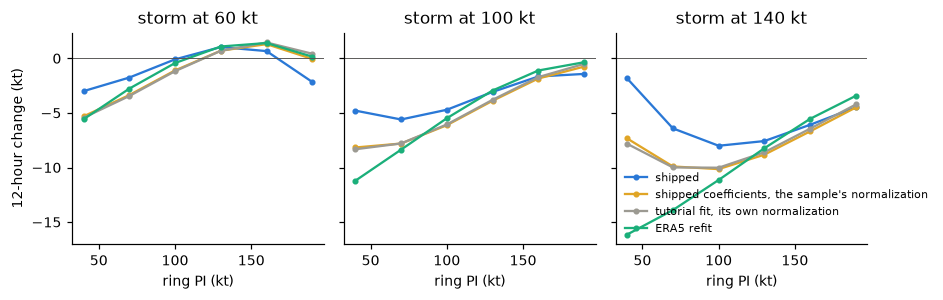

In [6]:
winds, pis = (60, 100, 140), (40, 70, 100, 130, 160, 190)
fits = {
    'shipped': shipped['w'],
    "shipped coefficients, the sample's normalization": {
        **tutorial['w'],
        'params': shipped['w']['params'],
    },
    'tutorial fit, its own normalization': tutorial['w'],
    'ERA5 refit': era5['w'],
}
resp = pd.DataFrame(
    {
        (name, wind): [
            refit.response(
                fit['params'], fit['meanX'], fit['stdX'], fit['meanY'], fit['stdY'], wind, pi
            )
            for pi in pis
        ]
        for name, fit in fits.items()
        for wind in winds
    },
    index=pd.Index(pis, name='ring PI (kt)'),
)
fig, axes = plt.subplots(1, len(winds), figsize=(9, 2.8), sharey=True)
for ax, wind in zip(axes, winds):
    for name, color in zip(fits, ('#2a78d6', '#e0a526', '#9c9a92', '#1baf7a')):
        ax.plot(pis, resp[(name, wind)], color=color, label=name, marker='o', ms=3)
    ax.axhline(0, color='#52514e', lw=0.6)
    ax.set_title(f'storm at {wind} kt')
    ax.set_xlabel('ring PI (kt)')
axes[0].set_ylabel('12-hour change (kt)')
axes[-1].legend(frameon=False, fontsize=7)
fig.tight_layout()
resp.T.round(1)

## 4. Refitting the regressions on ERA5

`ocr.risks.hurricane.refit` fits both regressions as that script does, on our ERA5 environment along the tutorial's observed tracks
of 1981–2012, and writes the normalization of its own sample. Land is read as `--land fine` reads
it; the tutorial file's fit uses its 300 km land mean. Water steps fit about as well as with the
tutorial file (R² 0.395 against 0.392), and land steps better (0.537 against 0.455).

In [7]:
pd.DataFrame(
    {
        (name, {'w': 'water', 'l': 'land'}[tag]): {
            'steps': fit[tag]['n'],
            'R2': fit[tag]['r2'],
            'rmse (kt)': fit[tag]['rmse'],
        }
        for name, fit in (('tutorial file', tutorial), ('ERA5', era5))
        for tag in 'wl'
    }
).style.format('{:.3f}')

CHAZ adds to each 12-hour step an error drawn from the regression's errors on observed steps that
start in the same 10 kt wind bin. Those errors also depend on PI. At 60–100 kt, steps in the top
third of ring PI gain 2.9–3.4 kt more than predicted, and gain more than 10 kt above the prediction
in 0.21–0.22 of steps, against 0.09 in the bottom third. `--intensity refit-pi` draws the error
from steps in the same wind bin and tercile of ring PI.

They depend on the basin too. At 64–96 kt over water, observed storms gain more than predicted in
the North Indian Ocean (+4.1 kt), the North Atlantic (+1.8) and the western Pacific (+1.6) than in
the Southern Hemisphere (+0.4) and the eastern Pacific (+0.3). `--intensity refit-basin` draws from
the steps of the same basin as well.

In [8]:
residuals = refit.residuals_by_pi(era5).loc['w']
residuals.style.format(
    {
        'n': '{:.0f}',
        'PI median': '{:.0f}',
        'mean': '{:+.1f}',
        'sd': '{:.1f}',
        'P(> +10 kt)': '{:.2f}',
    }
).set_caption(
    'ERA5 refit, water regression: observed minus predicted 12-hour change (kt), by starting '
    'wind and tercile of ring PI'
)

In [9]:
steps = refit.predictions(era5, era5_env, meanstd.YEARS)
hurricane_steps = steps[(steps['v0'] >= 64) & (steps['v0'] < 96)]
by_basin = hurricane_steps.groupby(['regression', 'basin'])['residual']
pd.DataFrame({'steps': by_basin.size(), 'mean (kt)': by_basin.mean()}).unstack(0).style.format(
    {
        ('steps', 'w'): '{:.0f}',
        ('steps', 'l'): '{:.0f}',
        ('mean (kt)', 'w'): '{:+.1f}',
        ('mean (kt)', 'l'): '{:+.1f}',
    }
).set_caption('ERA5 refit: observed minus predicted 12-hour change at 64-96 kt, 1981-2012')

Against `--land fine` alone, the refit lifts major time in the Philippine Sea from 0.27 to 0.48 of
observed and cuts the excess north of 35°N in the western Pacific from 168 to 71 times observed at
96 kt. In the North
Atlantic it loses ground: hurricane time in the Gulf falls from 0.99 to 0.70 of observed (1.00 to
0.67 without the scaling), and US hurricane landfalls from 0.62 to 0.53 (0.62 to 0.50).

Of the three refits, refit-basin comes closest in the North Atlantic: US landfalls 0.96 of
observed, hurricane landfalls 0.64 and Gulf hurricane time 0.86. It makes more North Atlantic
storms than observed, so the scaling lowers these by 5%; without it they are 1.00, 0.67 and 0.91.
US major landfalls fall, from 0.68 of observed with `--land fine` to 0.50 (0.53 without the
scaling). In the western Pacific refit-basin brings major time in the Philippine Sea to 0.82 and
Philippine hurricane landfalls to 0.64. It overshoots in the Southern Hemisphere: major time is
2.3 times observed in the South Pacific and 1.8 times in the Australian region, as with refit-pi
(2.5 and 2.0).

In [10]:
options = ['shipped', 'fine land', 'refit', 'refit-pi', 'refit-basin']
key_rows = (
    [f'Atl+Gulf landfalls >= {threshold} kt' for threshold in (34, 64, 96)]
    + ['NA share peak >= 64 kt', 'NA share peak >= 96 kt']
    + [
        f'NA time >= {threshold}: {region}'
        for threshold in (64, 96)
        for region in validate.NA_REGIONS
    ]
    + [f'time {region} >= {threshold}' for threshold in (64, 96) for region in validate.REGIONS]
    + [
        f'landfall {country} >= 64'
        for country in ('PHL', 'CHN', 'TWN', 'JPN', 'VNM', 'MEX', 'AUS', 'IND')
    ]
)
vs_observed(key_rows, options).style.format('{:.2f}').set_caption(
    'IBTrACS per year and each option over IBTrACS, 1981-2019'
)

,IBTrACS per yr,shipped,fine land,refit,refit-pi,refit-basin
Atl+Gulf landfalls >= 34 kt,3.08,0.89,0.90,0.90,0.87,0.96
Atl+Gulf landfalls >= 64 kt,1.36,0.60,0.62,0.53,0.51,0.64
Atl+Gulf landfalls >= 96 kt,0.26,0.67,0.68,0.42,0.43,0.50
NA share peak >= 64 kt,0.51,0.91,0.92,0.81,0.78,0.95
NA share peak >= 96 kt,0.21,0.96,0.99,0.83,0.83,0.97
NA time >= 64: Gulf,10.28,0.92,0.99,0.70,0.68,0.86
NA time >= 64: Caribbean,11.97,0.64,0.65,0.67,0.71,0.80
NA time >= 64: W Atlantic,29.31,0.53,0.54,0.55,0.57,0.67
NA time >= 64: MDR,18.23,0.56,0.56,0.64,0.67,0.77
NA time >= 64: Subtropical,23.87,0.69,0.68,0.61,0.56,0.87


In [11]:
na_scaled = [f'Atl+Gulf landfalls >= {threshold} kt' for threshold in (34, 64, 96)] + [
    f'NA time >= {threshold}: {region}' for threshold in (64, 96) for region in validate.NA_REGIONS
]
sets = ['CHAZ team', *options]
scaling = rates.loc['NA TS storms/yr', 'IBTrACS'] / rates.loc['NA TS storms/yr', sets]
unscaled = (
    rates.loc[na_scaled, sets].div(scaling, axis=1).div(rates.loc[na_scaled, 'IBTrACS'], axis=0)
)
pd.concat([scaling.to_frame('scaling factor').T, unscaled]).style.format('{:.2f}').set_caption(
    'North Atlantic quantities over IBTrACS without the scaling to the observed North Atlantic '
    'storm count, 1981-2019, and the factor the scaled ratios carry'
)

,CHAZ team,shipped,fine land,refit,refit-pi,refit-basin
scaling factor,1.05,1.01,1.00,1.05,1.07,0.95
Atl+Gulf landfalls >= 34 kt,0.68,0.88,0.90,0.85,0.82,1.00
Atl+Gulf landfalls >= 64 kt,0.42,0.59,0.62,0.50,0.47,0.67
Atl+Gulf landfalls >= 96 kt,0.43,0.66,0.68,0.40,0.40,0.53
NA time >= 64: Gulf,0.60,0.91,1.00,0.67,0.64,0.91
NA time >= 64: Caribbean,0.63,0.63,0.66,0.64,0.67,0.84
NA time >= 64: W Atlantic,0.50,0.53,0.54,0.52,0.53,0.71
NA time >= 64: MDR,0.55,0.55,0.56,0.61,0.62,0.81
NA time >= 64: Subtropical,0.54,0.68,0.68,0.58,0.52,0.91
NA time >= 64: north of 45N,0.70,2.21,2.23,0.67,0.45,1.22


## 5. Score and a test on years the fit did not see

`validate.score` puts these together as the mean |ln(set / IBTrACS)| over 41 metrics: US Atlantic
and Gulf landfalls at 34, 64 and 96 kt; the North Atlantic shares of storms peaking at 64 and
96 kt; time at 64 and 96 kt in five North Atlantic regions and nine others; and hurricane
landfalls in eight countries, with landfalls counted by the first-crossing rule. High latitudes
are left out. A set with none of something observed counts as 0.05 of it (every ratio is floored
at 0.05). As in Emanuel (2025)'s tests, a count scores only where IBTrACS has more than 5 events
in the period: over 1981–1999 this leaves out US major landfalls, over 2000–2019 India's
hurricane landfalls, and over the shorter periods both. Lower is better. Over 2000–2019
refit-basin scores 0.323, the shipped run 0.454 and the CHAZ team's set 0.402. Counting
landfalls at the strongest crossing and last offshore wind instead gives 0.309, 0.451 and 0.378,
in the same order. The score leaves out the high latitudes, where refit-basin is still far too
intense, and counts US major landfalls, which refit-basin lowers, as one metric.

In [12]:
PERIODS = {
    '1981-1999': range(1981, 2000),
    '2000-2019': range(2000, 2020),
    '2000-2012': range(2000, 2013),
    '2013-2019': range(2013, 2020),
}
RULES = {
    'first crossing (Emanuel 2025)': validate.SCORED,
    'strongest crossing, last offshore wind': validate.SCORED_OFFSHORE,
}
scores, n_scored = {}, {}
for rule, scored in RULES.items():
    for period, years in PERIODS.items():
        period_rates = validate.metrics(tables, years)
        keep = validate.eligible(period_rates, len(years), scored)
        scores[(rule, period)] = validate.score(period_rates, keep)
        n_scored[(rule, period)] = len(keep)
        left_out = [metric for metric in scored if metric not in keep]
        if left_out:
            print(f'{rule}, {period}: left out {left_out}')
scores = pd.DataFrame(scores).T
scores['metrics scored'] = pd.Series(n_scored)
scores.style.format('{:.3f}').format('{:.0f}', subset=['metrics scored']).set_caption(
    f'Mean |ln(source / IBTrACS)| over the {len(validate.SCORED)} metrics, leaving out counts'
    f' IBTrACS has {validate.MIN_EVENTS} or fewer of in the period (lower is better)'
)

first crossing (Emanuel 2025), 1981-1999: left out ['Atl+Gulf landfalls >= 96 kt']
first crossing (Emanuel 2025), 2000-2019: left out ['landfall IND >= 64']
first crossing (Emanuel 2025), 2000-2012: left out ['Atl+Gulf landfalls >= 96 kt', 'landfall IND >= 64']
first crossing (Emanuel 2025), 2013-2019: left out ['Atl+Gulf landfalls >= 96 kt', 'landfall IND >= 64']
strongest crossing, last offshore wind, 2000-2012: left out ['landfall IND >= 64, offshore']
strongest crossing, last offshore wind, 2013-2019: left out ['Atl+Gulf landfalls >= 96 kt, offshore']


The refits are fit on the observed tracks of 1981–2012, so their scores over those years are
partly in sample. `--fit 1981-1999` fits refit-basin on 1981–1999 only. Over 2013–2019, which
neither fit saw, the fit on 1981–1999 scores 0.317, the fit on 1981–2012 0.332 and `--land fine`
alone 0.465. Over 2000–2019 the fit on 1981–1999 scores 0.310 against 0.439 for `--land fine`.
Resampling the years, the same years for every set, puts the median paired difference between
the fit on 1981–1999 and `--land fine` over 2000–2019 at 0.113 in favour of the fit, with 90% of
resamples between 0.045 and 0.162. `--land fine` scores 0.439 against the shipped run's 0.454;
the paired median is 0.011 in its favour, and 90% of resamples lie between 0.020 in its favour and
0.001 against. Each resample scores the metrics eligible over the whole period, leaves out any
with no observed event in that resample, and floors every ratio at 0.05. The resamples measure how the scores vary from
year to year for these runs, not how the fits would vary.

The later years are not wholly outside the comparison. The seeding ratio counts the observed
storms of 1981–2005. The scaled North Atlantic quantities divide by each set's own North Atlantic
storm count, which the intensity option changes (12.5 to 14.1 a year across the refits), and
multiply by the observed count of the period scored. Our run also makes more storms
in 2000–2019 than in 1981–1999, while the observed count stays level
([landfall-weights.ipynb](landfall-weights.ipynb), section 4). And we chose which options to compare after
looking at all of 1981–2019. Last, the refits learn from the tutorial's observed-track file
(`bt_global_predictors.nc`) and are scored against IBTrACS as we read it, so where the two
records differ, the difference may affect the refits' scores.

In [13]:
pairs = [
    ('refit-basin, fit 1981-1999', 'fine land'),
    ('refit-basin, fit 1981-1999', 'refit-basin'),
    ('refit-basin', 'fine land'),
    ('fine land', 'shipped'),
]
rows = {}
for period in ('2000-2019', '2013-2019'):
    resampled = validate.bootstrap(tables, PERIODS[period], n=2000, seed=0)
    for first, second in pairs:
        difference = resampled[first] - resampled[second]
        rows[(period, f'{first} − {second}')] = {
            'median': difference.median(),
            '5%': difference.quantile(0.05),
            '95%': difference.quantile(0.95),
            'P(< 0)': (difference < 0).mean(),
        }
pd.DataFrame(rows).T.style.format('{:+.3f}').set_caption(
    'Paired score differences over 2,000 resamples of whole years (negative: the first scores better)'
)

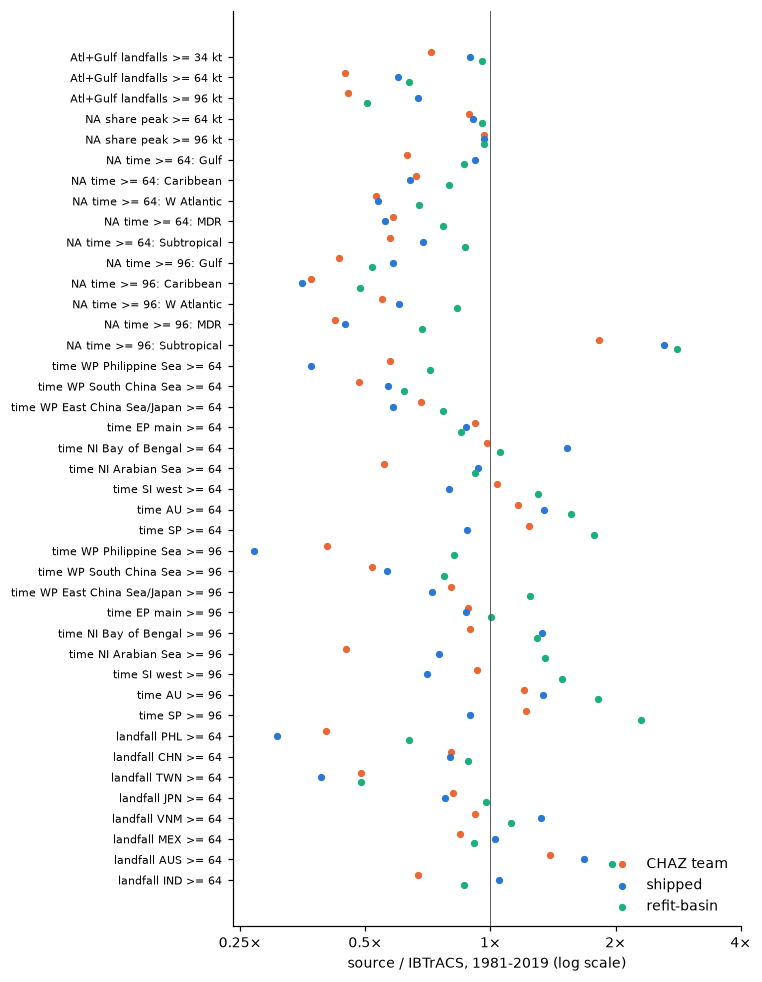

In [14]:
scored_rates = rates.loc[validate.SCORED]
log_ratio = np.log(
    scored_rates.drop(columns='IBTrACS')
    .div(scored_rates['IBTrACS'], axis=0)
    .clip(lower=validate.FLOOR)
)
show = ['CHAZ team', 'shipped', 'refit-basin']
fig, ax = plt.subplots(figsize=(7, 9))
rows_y = np.arange(len(log_ratio))
for offset, name in enumerate(show):
    ax.scatter(log_ratio[name], rows_y + (offset - 1) * 0.22, s=14, color=COLORS[name], label=name)
ax.axvline(0, color='#52514e', lw=0.6)
ax.set_yticks(rows_y, log_ratio.index, fontsize=7)
ax.invert_yaxis()
ticks = [0.25, 0.5, 1, 2, 4]
ax.set_xticks(np.log(ticks), [f'{tick:g}×' for tick in ticks])
ax.set_xlabel('source / IBTrACS, 1981-2019 (log scale)')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()

## 6. Misses after the refit

Some misses survive every option:

- The Southern Hemisphere excess is there already where members first reach 34 kt: 1.33 times
  the observed number in the South Pacific with the shipped run, and 1.93 times with refit-basin,
  which brings more members to 34 kt.
- High latitudes. With refit-basin, fewer storms first reach 34 kt there: south of 30°S the
  count falls from 13.2 to 6.9 times observed, and north of 35°N in the western Pacific from
  12.5 to 4.9 times. Hurricane time there is still 5.3 and 3.4 times observed.
- North Atlantic majors: 2.8 times the observed time in the subtropics (3.0 without the scaling)
  and 0.52 in the Gulf (0.54).
- Taiwan's hurricane landfalls, at 0.49 of observed.

In [15]:
left = (
    [
        f'TS formed {region}'
        for region in ('SP', 'AU', 'SI west', 'SH south of 30S', 'WP north of 35N')
    ]
    + ['time SP >= 96', 'time AU >= 96', 'time SH south of 30S >= 64', 'time WP north of 35N >= 64']
    + ['NA time >= 96: Subtropical', 'NA time >= 96: north of 45N', 'NA time >= 96: Gulf']
    + ['landfall TWN >= 64', 'Atl+Gulf landfalls >= 96 kt']
)
vs_observed(left, ['shipped', 'refit-basin']).style.format('{:.2f}')

,IBTrACS per yr,shipped,refit-basin
TS formed SP,6.74,1.33,1.93
TS formed AU,10.69,1.04,1.20
TS formed SI west,9.56,1.03,1.26
TS formed SH south of 30S,0.08,13.23,6.92
TS formed WP north of 35N,0.08,12.51,4.91
time SP >= 96,13.10,0.90,2.30
time AU >= 96,12.69,1.34,1.81
time SH south of 30S >= 64,1.97,13.21,5.31
time WP north of 35N >= 64,4.00,7.41,3.42
NA time >= 96: Subtropical,1.69,2.62,2.81


## Summary

| | proposed | evidence |
| --- | --- | --- |
| land term | `--land fine`: land at the storm's position on the 1/12° mask | section 2; the refits are fit on it |
| intensity | `--intensity refit-basin`: regressions refit on ERA5 along the observed tracks of 1981–2012, random error drawn by basin, wind and ring PI | sections 4 and 5: with landfalls counted by the first-crossing rule, the fit on 1981–2012 scores 0.323 over 2000–2019 and 0.332 over 2013–2019, which no fit saw, against 0.439 and 0.465 for `--land fine` alone; the fit on 1981–1999 scores lower (better) in both, 0.310 and 0.317. The ranking is the same with landfalls counted at the strongest crossing and last offshore wind |

Against it: US major landfalls fall from 0.68 of observed with `--land fine` to 0.50, major time in
the South Pacific rises to 2.3 times observed, and the score leaves out the high latitudes.

Open:

- **A regional calibration.** No option here fixes the Southern Hemisphere overshoot, US
  hurricane landfalls (0.64 of observed with refit-basin, 0.67 without the scaling) or the high
  latitudes. Genesis comes
  first: `chaz --genesis calibrated` scales TCGI by region, but its map was fit on an earlier run
  and needs refitting on the configuration chosen here. A regional adjustment of intensity would
  come after it.
- **Climate-model runs.** The refits are fit on ERA5 and run only on ERA5 forcing. A climate model
  needs its own normalization of the refit regressions, as it does for the shipped ones
  ([cmip.ipynb](cmip.ipynb)).